# External Validation 
**External validation for the Pulmonary Tb  model**

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

In [10]:
from fastai.vision.all import *
from fastai.data import *

In [11]:
from pathlib import Path 
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score)
import numpy as np

In [18]:
learner = load_learner('/Users/akankshagupta/Desktop/TB ML model /tb1_model.pkl')
print(learner.dls.vocab)

['Normal', 'Tuberculosis']


/Users/akankshagupta/ml-env/lib/python3.14/site-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


In [19]:
from pathlib import Path
from fastai.vision.all import *

data_path = Path("/Users/akankshagupta/Desktop/TB ML model /dataset 2.0 ")

image_paths = []
true_labels = []

for folder in data_path.iterdir():
    if folder.is_dir():
        label = folder.name.strip()

        for img in get_image_files(folder):
            image_paths.append(img)
            true_labels.append(label)

print("Total images:", len(image_paths))
print("Normal images:", true_labels.count("Normal"))
print("TB-positive images:", true_labels.count("Tuberculosis"))

Total images: 3008
Normal images: 514
TB-positive images: 2494


In [20]:
predicted_labels = []

for img in image_paths:
    prediction, _, probabilities = learner.predict(img)
    predicted_labels.append(str(prediction))

print("Predictions completed:", len(predicted_labels))

Predictions completed: 3008


Accuracy: 0.6808510638297872

Classification Report:
              precision    recall  f1-score   support

      Normal       0.35      0.97      0.51       514
Tuberculosis       0.99      0.62      0.76      2494

    accuracy                           0.68      3008
   macro avg       0.67      0.79      0.64      3008
weighted avg       0.88      0.68      0.72      3008


Confusion Matrix:
[[ 497   17]
 [ 943 1551]]


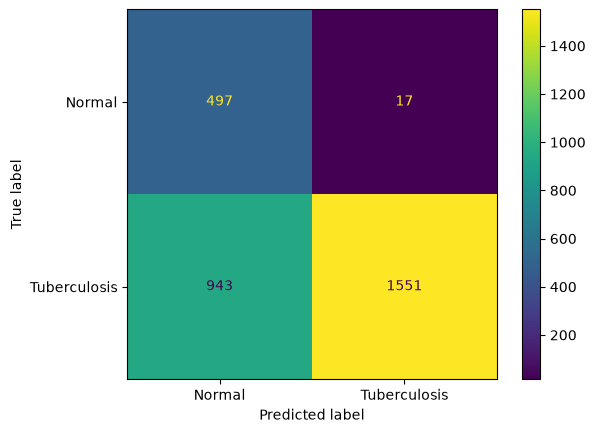

In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

labels = ["Normal", "Tuberculosis"]

print("Accuracy:", accuracy_score(true_labels, predicted_labels))

print("\nClassification Report:")
print(classification_report(
    true_labels,
    predicted_labels,
    labels=labels,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    true_labels,
    predicted_labels,
    labels=labels
))
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(true_labels, predicted_labels, labels=['Normal', 'Tuberculosis'])
plt.show()

## External Validation and Dataset Shift

The ResNet-18 model achieved **99.0% accuracy on its original validation dataset**, with 94.3% sensitivity for tuberculosis detection and 100% specificity for normal cases. However, evaluation on an independent dataset containing 3,008 chest X-ray images revealed a substantial performance decline, with accuracy falling to **68.1%**.

On the external dataset, the model achieved 62.2% sensitivity for tuberculosis and 96.7% specificity for normal cases. It correctly identified 1,551 of 2,494 tuberculosis-positive images but misclassified 943 as normal, representing a substantial false-negative burden. This discrepancy suggests limited generalizability and may reflect dataset shift, differences in image acquisition or patient populations, or potential shortcut learning. Further investigation is required to determine the underlying causes.

These findings highlight the importance of independent external validation before considering medical AI models for clinical use. High accuracy on an original dataset does not necessarily translate into reliable performance across different clinical settings.


In [11]:
from pathlib import Path

# Export the trained model
learner.export("tb_model_external_validation.pkl")

print("Model exported successfully!")

Model exported successfully!
